# importation

In [1]:
import gc
import time
import pandas as pd # type: ignore
print("pandas imported")
import numpy as np
print("numpy imported")
import os
print("os imported")
from pathlib import Path
print("path imported")
import cv2
print("cv imported")
import matplotlib.pyplot as plt
print("plt imported")
from sklearn.preprocessing import LabelEncoder
print("encoder imported")

import json
print("json imported")

import tensorflow as tf
from tensorflow.keras import layers, models # type: ignore
from tensorflow.keras.utils import to_categorical # type: ignore
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau # type: ignore

print("tensorflow imported")

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)
from sklearn.model_selection import train_test_split


data_dir = Path("../data/raw")
img_size = (224, 224) 
random_state=42
valid_ext = (".jpeg", ".jpg", ".bmp", ".png")

pandas imported
numpy imported
os imported
path imported
cv imported
plt imported
encoder imported
json imported
tensorflow imported


# Chargement et Prétraitement du Dataset

In [2]:
class_names = sorted([
    folder.name
    for folder in data_dir.iterdir()
    if folder.is_dir()
])

print("Classes:", class_names)
print("Number of classes:", len(class_names))

Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']
Number of classes: 4


In [3]:
for class_name in class_names:
    class_dir = data_dir / class_name

    image_files = [
        file for file in class_dir.iterdir()
        if file.is_file() and file.suffix.lower() in valid_ext
    ]

    print(f"{class_name}: {len(image_files)} images ")


glioma: 1621 images 
meningioma: 1645 images 
notumor: 2000 images 
pituitary: 1757 images 


In [4]:
X = []
labels = []

for class_name in class_names:

    class_dir = data_dir / class_name

    for image_path in class_dir.iterdir():

        if not image_path.is_file():
            continue

        if image_path.suffix.lower() not in valid_ext:
            continue

        try:
          
            image = cv2.imread(str(image_path))

            if image is None:
                print(f"Could not load: {image_path}")
                continue

            image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

            image = cv2.resize(image, img_size)

            X.append(image)
            labels.append(class_name)

        except (cv2.error, OSError, ValueError) as error:
            print(f"Error with {image_path}: {error}")

    print(f"Finished class: {class_name}")

print("\nTotal images:", len(X))
print("Total labels:", len(labels))
if X:
    print("Image shape:", X[0].shape)
    print("First label:", labels[0])

Finished class: glioma
Finished class: meningioma
Finished class: notumor
Finished class: pituitary

Total images: 7023
Total labels: 7023
Image shape: (224, 224, 3)
First label: glioma


In [5]:
X = np.array(X, dtype=np.uint8)
y = np.array(labels)

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Image data type:", X.dtype)
print("Classes:", np.unique(y))

X shape: (7023, 224, 224, 3)
y shape: (7023,)
Image data type: uint8
Classes: ['glioma' 'meningioma' 'notumor' 'pituitary']


In [6]:
unique_classes, class_counts = np.unique(
    y,
    return_counts=True
)

for class_name, count in zip(unique_classes, class_counts):
    print(f"{class_name}: {count} images")

glioma: 1621 images
meningioma: 1645 images
notumor: 2000 images
pituitary: 1757 images


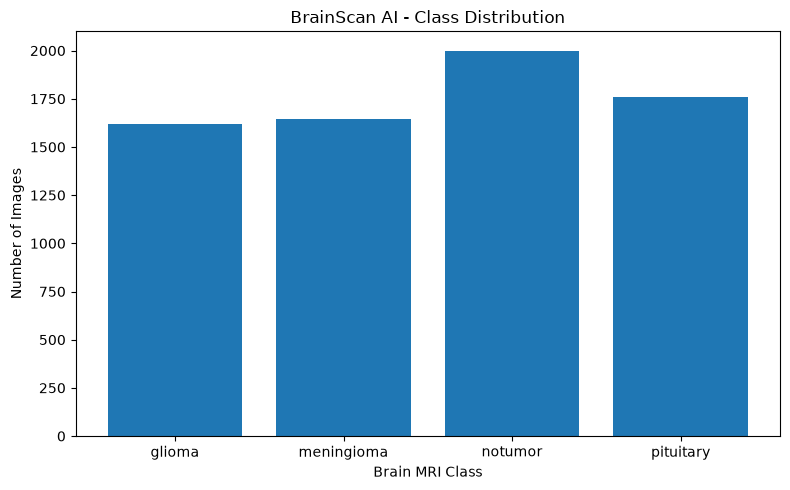

In [7]:
plt.figure(figsize=(8, 5))

plt.bar(unique_classes, class_counts)

plt.title("BrainScan AI - Class Distribution")
plt.xlabel("Brain MRI Class")
plt.ylabel("Number of Images")


plt.tight_layout()
plt.show()

In [8]:
X = X.astype(np.float32) / 255.0
print("Minimum pixel value:", X.min())
print("Maximum pixel value:", X.max())

Minimum pixel value: 0.0
Maximum pixel value: 1.0


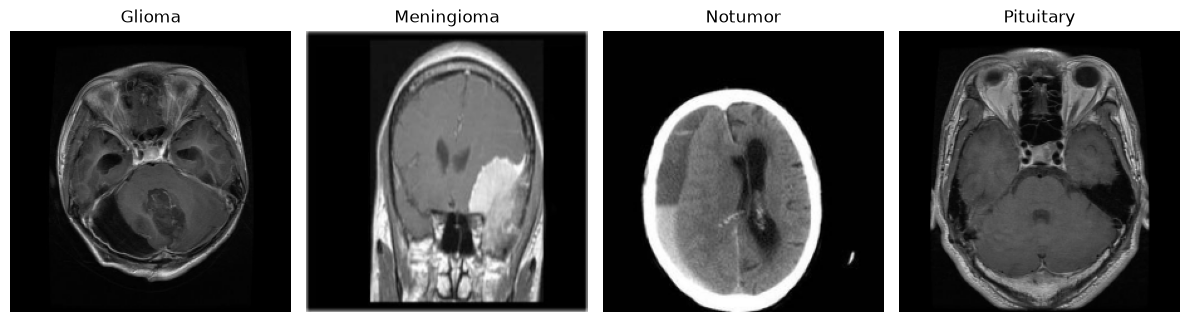

In [9]:
# Show sample images per class
plt.figure(figsize=(12, 6))
for idx, class_name in enumerate(class_names):
    # Find first image index of this class
    class_idx = np.where(y == class_name)[0][0]
    
    plt.subplot(1, 4, idx + 1)
    plt.imshow(X[class_idx])
    plt.title(f"{class_name.capitalize()}")
    plt.axis("off")

plt.tight_layout()
plt.show()


In [10]:


# label encoding (0, 1, 2, 3)
label_encoder = LabelEncoder()
y_integers = label_encoder.fit_transform(labels)

class_mapping = {int(i): str(c) for i, c in enumerate(label_encoder.classes_)}
with open("../models/class_labels.json", "w") as f:
    json.dump(class_mapping, f, indent=4)
print("Saved class mapping:", class_mapping)

#One-Hot encoding: [1,0,0,0] for class 0, [0,1,0,0] for class 1 help in final output layer of the model [0.05,0.8,0.05,0.1] 5% glioma 5% notumor 80% meningioma 10% pituitary
y_categorical = to_categorical(y_integers, num_classes=len(class_names))
print("y_categorical shape:", y_categorical.shape)


Saved class mapping: {0: 'glioma', 1: 'meningioma', 2: 'notumor', 3: 'pituitary'}
y_categorical shape: (7023, 4)


# Conception du Modèle CNN

In [11]:


# 80% Train+Validation, 20% Test
X_train_val, X_test, y_train_val_idx, y_test_idx = train_test_split(
    X, y_integers, test_size=0.20, random_state=random_state, stratify=y_integers, shuffle=True
)

# Train (70% total) and Validation (10% total)
X_train, X_val, y_train_idx, y_val_idx = train_test_split(
    X_train_val, y_train_val_idx, test_size=0.125, random_state=random_state, stratify=y_train_val_idx, shuffle=True
)

# Convert to One-Hot
y_train = to_categorical(y_train_idx, num_classes=4)
y_val = to_categorical(y_val_idx, num_classes=4)
y_test = to_categorical(y_test_idx, num_classes=4)

print(f"Train set: {X_train.shape} | Labels: {y_train.shape}")
print(f"Val set:   {X_val.shape} | Labels: {y_val.shape}")
print(f"Test set:  {X_test.shape} | Labels: {y_test.shape}")


Train set: (4915, 224, 224, 3) | Labels: (4915, 4)
Val set:   (703, 224, 224, 3) | Labels: (703, 4)
Test set:  (1405, 224, 224, 3) | Labels: (1405, 4)


In [12]:


def build_cnn_model(input_shape=(224, 224, 3), num_classes=4):
    model = models.Sequential([
        layers.Input(shape=input_shape),
        # Block 1
        layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.25),
        
        # Block 2
        layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.25),
        
        # Block 3
        layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.25),
        
        # Classification Head
        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.50),
        layers.Dense(num_classes, activation='softmax')
    ])
    return model

model = build_cnn_model(input_shape=(224, 224, 3), num_classes=4)


In [13]:
# print summary table
model.summary()



Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 100352)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    12,845,184 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,938,948 (49.36 MB)

 Trainable params: 12,938,948 (49.36 MB)

 Non-trainable params: 0 (0.00 B)

In [14]:

# Ensure models directory exists
os.makedirs("../models", exist_ok=True)

# 1. Compile Model
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# 2. Callbacks
callbacks = [
    ModelCheckpoint(
        filepath="../models/best_brain_tumor_model.h5",
        monitor="val_loss",
        save_best_only=True,
        mode="min",
        verbose=1
    ),
    EarlyStopping(
        monitor="val_loss",
        patience=6,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=3,
        min_lr=1e-6,
        verbose=1
    )
]

print("Model compiled with Adam and Callbacks configured.")


Model compiled with Adam and Callbacks configured.


In [15]:


# batch_size = 32
# epochs = 25

# start_time = time.time()

# history = model.fit(
#     X_train, y_train,
#     epochs=epochs,
#     batch_size=batch_size,
#     validation_data=(X_val, y_val),
#     callbacks=callbacks,
#     verbose=1
# )

# seconds_total = time.time() - start_time
# print("Training time:", int(seconds_total // 60), "min", int(seconds_total % 60), "sec")

In [16]:
test_loss, test_accuracy = model.evaluate(X_test, y_test)
print("Test accuracy:", test_accuracy)

44/44 ━━━━━━━━━━━━━━━━━━━━ 18s 395ms/step - accuracy: 0.2413 - loss: 1.3955
Test accuracy: 0.24128113687038422


In [17]:
best_model = tf.keras.models.load_model(
    "../models/best_brain_tumor_model.h5"
)

test_loss, test_accuracy = best_model.evaluate(
    X_test, y_test,
)

print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.2%}")

44/44 ━━━━━━━━━━━━━━━━━━━━ 12s 238ms/step - accuracy: 0.9701 - loss: 0.1035
Test loss: 0.1035
Test accuracy: 97.01%


44/44 ━━━━━━━━━━━━━━━━━━━━ 15s 338ms/step


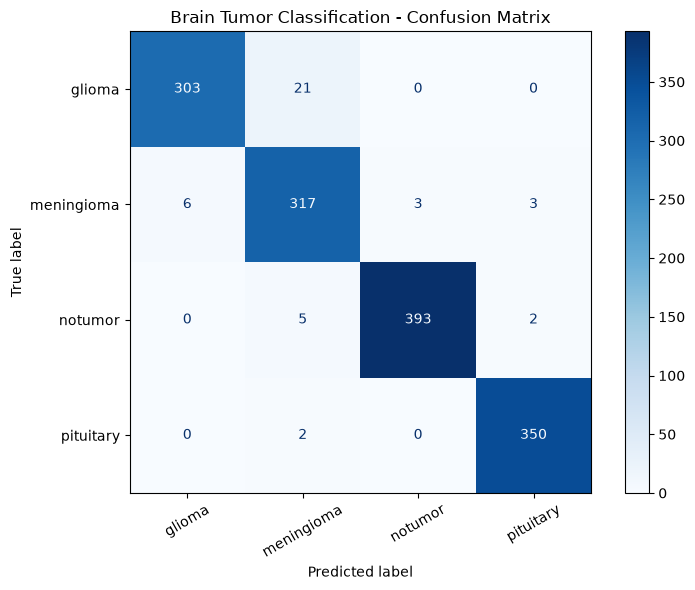

              precision    recall  f1-score   support

      glioma     0.9806    0.9352    0.9573       324
  meningioma     0.9188    0.9635    0.9407       329
     notumor     0.9924    0.9825    0.9874       400
   pituitary     0.9859    0.9943    0.9901       352

    accuracy                         0.9701      1405
   macro avg     0.9694    0.9689    0.9689      1405
weighted avg     0.9708    0.9701    0.9702      1405



In [18]:


class_names = ["glioma", "meningioma", "notumor", "pituitary"]

# Predict probabilities for every test image
y_prob = best_model.predict(X_test, verbose=1)

# Convert one-hot labels and probabilities to class indices
y_true = np.argmax(y_test, axis=1)
y_pred = np.argmax(y_prob, axis=1)

# Confusion matrix
cm = confusion_matrix(
    y_true, y_pred,
    labels=np.arange(len(class_names))
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(8, 6))
disp.plot(ax=ax, cmap="Blues", values_format="d")
plt.title("Brain Tumor Classification - Confusion Matrix")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# Classification report
print(classification_report(
    y_true,
    y_pred,
    labels=np.arange(len(class_names)),
    target_names=class_names,
    digits=4,
    zero_division=0
))

Correct: 1363
Incorrect: 42


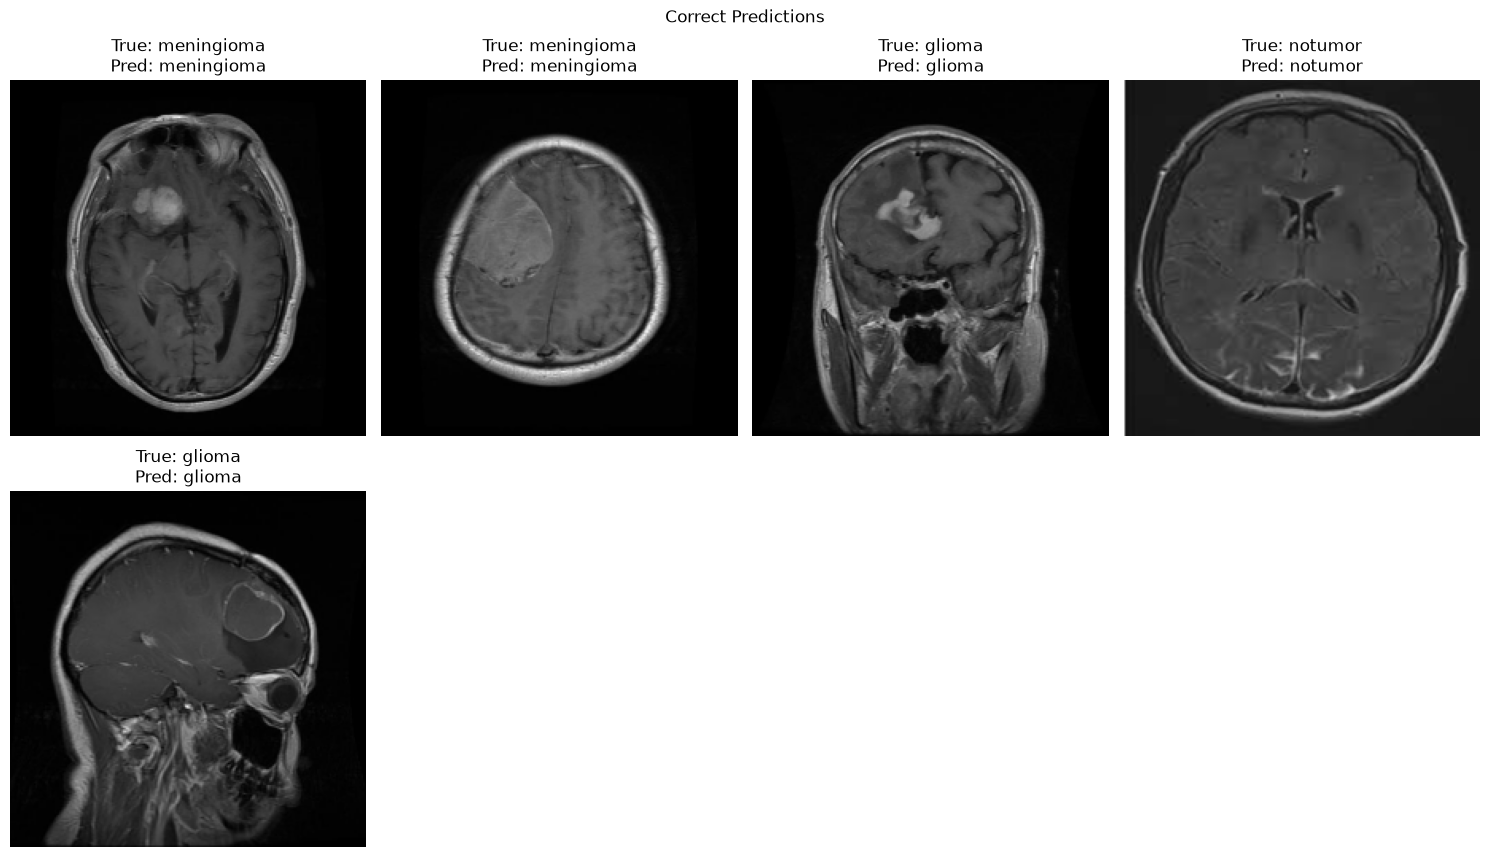

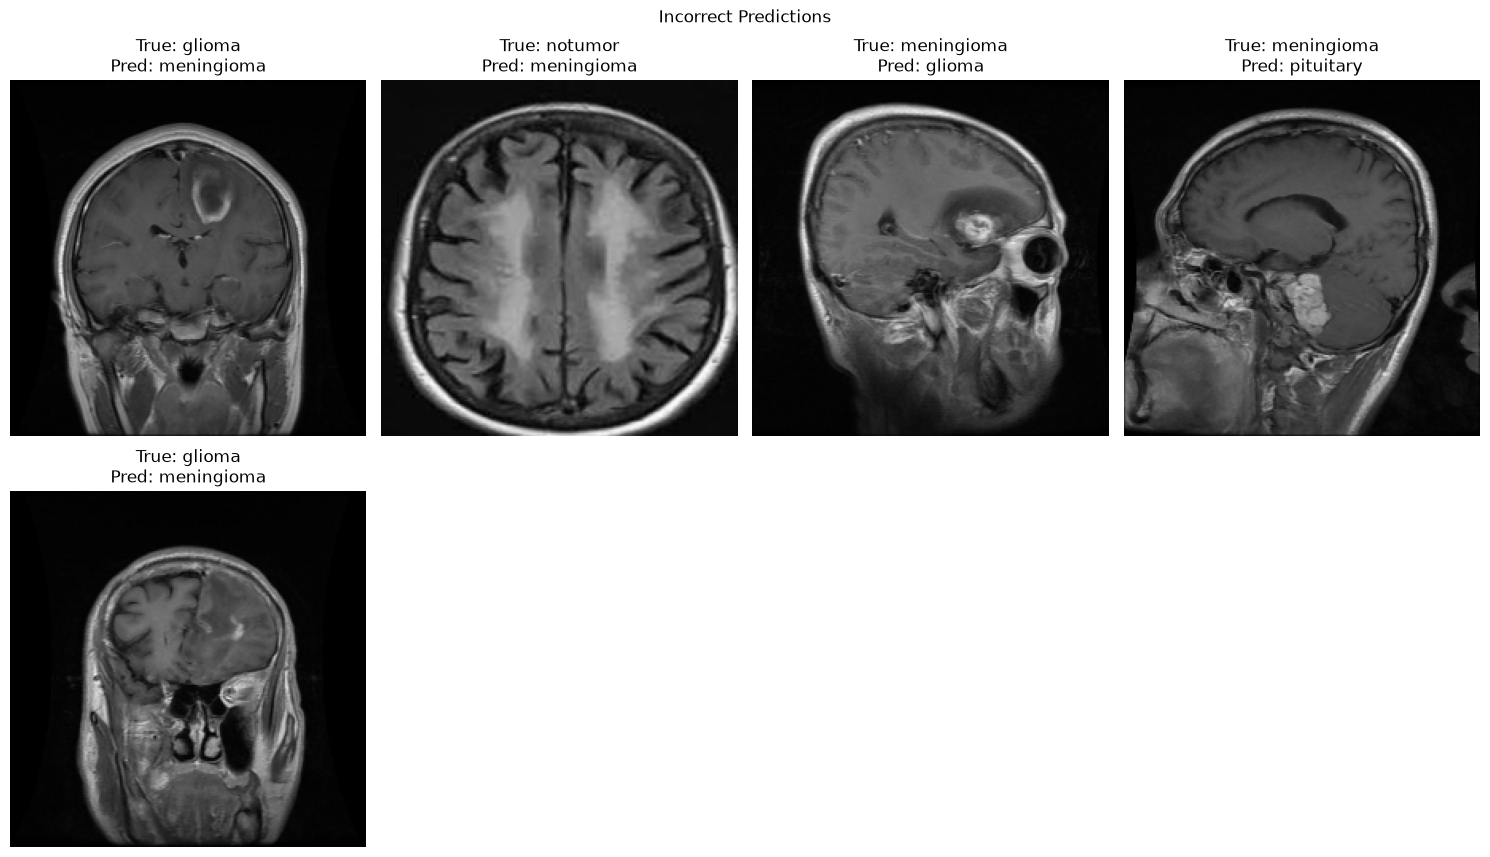

In [22]:
def show_predictions(indices, title):
    plt.figure(figsize=(15, 9))

    for i, idx in enumerate(indices[:5]):
        plt.subplot(2, 4, i + 1)
        plt.imshow(X_test[idx])

        actual = class_names[y_true[idx]]
        predicted = class_names[y_pred[idx]]

        plt.title(f"True: {actual}\nPred: {predicted}")
        plt.axis("off")

    plt.suptitle(title)
    plt.tight_layout()
    plt.show()


correct = np.where(y_true == y_pred)[0]
incorrect = np.where(y_true != y_pred)[0]

print("Correct:", len(correct))
print("Incorrect:", len(incorrect))

show_predictions(correct, "Correct Predictions")
show_predictions(incorrect, "Incorrect Predictions")